## Download IceBridge BedMachine Greenland, Version 7 ##

This notebook downloads bathymetry, bed elevation, glacier/ice thickness, terrain elevation from the [IceBridge BedMachine Greenland, Version 7](https://nsidc.org/data/idbmg4/versions/7) dataset. 

#### 1. Load packages and log in to NASA EarthData

Using the [NSIDCLoginNotebook.ipynb](https://github.com/fastice/GrIMPNotebooks/blob/master/NSIDCLoginNotebook.ipynb) to set up EarthData access and log in. 

Create an account at https://urs.earthdata.nasa.gov/users/new and use those credentials to log in. 

In [1]:
# import libraries and packages
%load_ext autoreload
%autoreload 2
import os
import dask
import panel
import pandas as pd
import nisardev as nisar
import xarray as xr
import matplotlib.pyplot as plt
from dask.diagnostics import ProgressBar
import geopandas as gpd
ProgressBar().register()
dask.config.set(num_workers=2)  # avoid problems with too many open connections at NSIDC
panel.extension() 

# Log in to NASA EarthData to access NSIDC data.
import earthaccess
earthaccess.login() 

In [18]:
# set data paths
# bed_machine path
bed_machine_path = "/Users/sofiasuhinin/Desktop/GrIS_Calving/data/BedMachine/BedMachineGreenland-v7.nc"
bedmachine = xr.open_dataset(bed_machine_path)

In [19]:
# define the bounding box for the bedmachine data based on the terminus/velocity data
    # these are the bounds from velocity observations
minx = -205600.0
miny = -2293800.0
maxx = -164600.0
maxy =  -2248800.0
margin = 15000

bbox = {"minx": minx-margin, "maxx": maxx+margin, "miny": miny-margin, "maxy": maxy + margin}
print("bbox:", bbox) #check

# subset bedmachine to ji
bedmachine_ji = bedmachine.sel(x=slice(minx, maxx), y=slice(maxy, miny))
bedmachine_ji

bbox: {'minx': -220600.0, 'maxx': -149600.0, 'miny': -2308800.0, 'maxy': -2233800.0}


<xarray.Dataset> Size: 2MB
Dimensions:    (x: 273, y: 300)
Coordinates:
  * x          (x) int32 1kB -205475 -205325 -205175 ... -164975 -164825 -164675
  * y          (y) int32 1kB -2248925 -2249075 -2249225 ... -2293625 -2293775
Data variables:
    mapping    |S1 1B ...
    mask       (y, x) int8 82kB ...
    surface    (y, x) float32 328kB ...
    thickness  (y, x) float32 328kB ...
    bed        (y, x) float32 328kB ...
    errbed     (y, x) float32 328kB ...
    source     (y, x) int8 82kB ...
    dataid     (y, x) int8 82kB ...
    geoid      (y, x) float32 328kB ...
    rgi        (y, x) int8 82kB ...
Attributes: (12/19)
    Conventions:                 CF-1.7, ACDD-1.3
    title:                       BedMachine Greenland v7
    creator_name:                Mathieu Morlighem
    creator_email:               mathieu.morlighem@dartmouth.edu
    creator_institution:         Department of Earth and Planetary Sciences, ...
    product_version:             v7.0
    ...                          ...
    references:                  Morlighem M. et al., (2017), BedMachine v3: ...
    keywords:                    EARTH SCIENCE > CRYOSPHERE > GLACIERS/ICE SH...
    summary:                     This dataset contains a bed topography/bathy...
    time_coverage_start:         1970-01-01
    time_coverage_end:           2019-10-01
    nominal_year:                2008

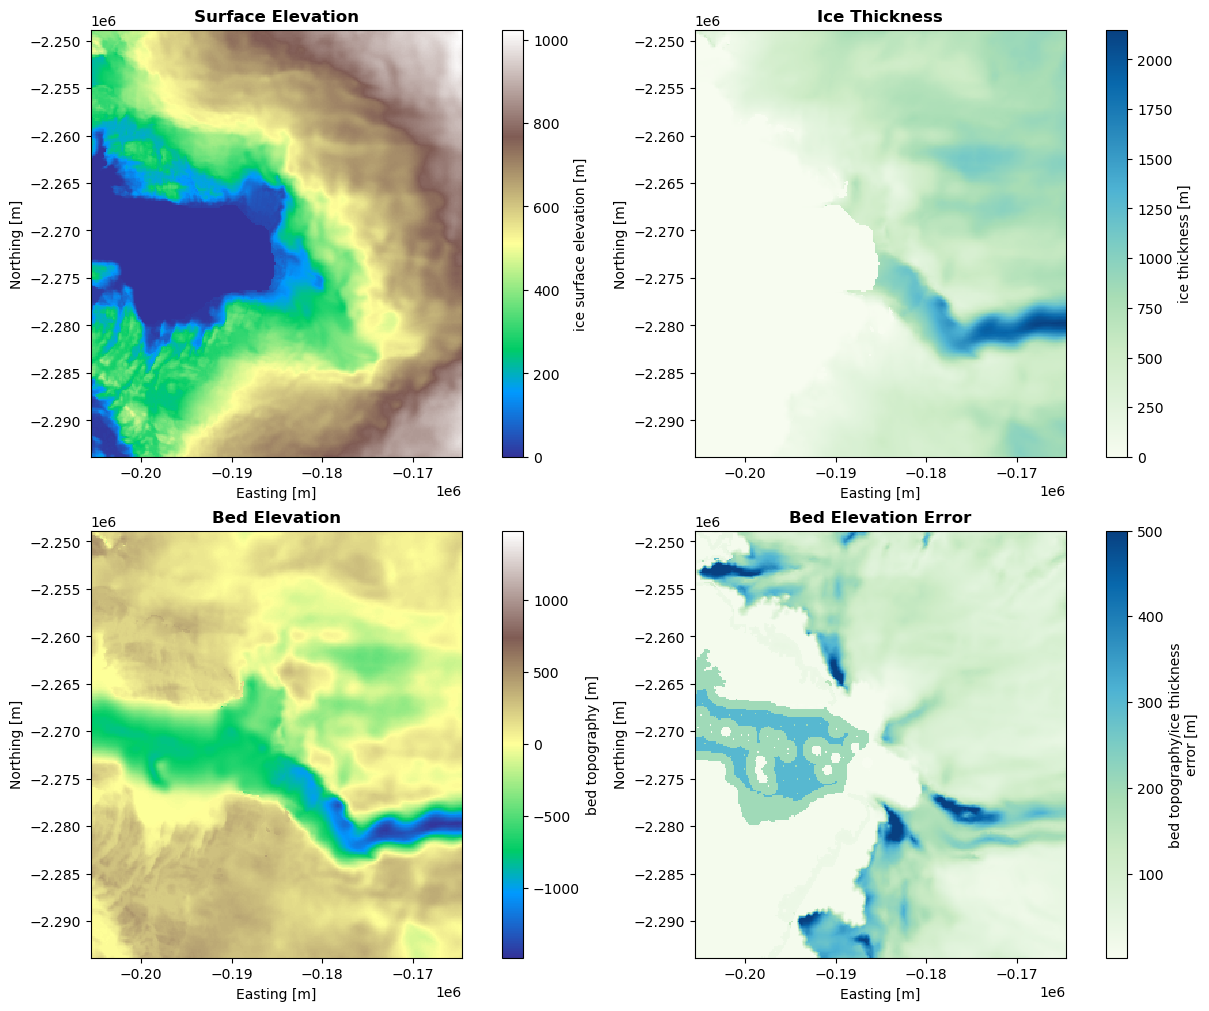

In [20]:
# plot verification of data
fig, ax = plt.subplots(2, 2, figsize=(12, 10), constrained_layout=True)

bedmachine_ji["surface"].plot(ax=ax[0, 0], cmap="terrain")
ax[0, 0].set_title("Surface Elevation", fontweight = "bold")

bedmachine_ji["thickness"].plot( ax=ax[0, 1], cmap="GnBu")
ax[0, 1].set_title("Ice Thickness", fontweight = "bold")

bedmachine_ji["bed"].plot(ax=ax[1, 0], cmap="terrain")
ax[1, 0].set_title("Bed Elevation", fontweight = "bold")

bedmachine_ji["errbed"].plot(ax=ax[1, 1], cmap="GnBu")
ax[1, 1].set_title("Bed Elevation Error", fontweight = "bold")


for a in ax.flat:
    a.set_xlabel("Easting [m]")
    a.set_ylabel("Northing [m]")
    a.ticklabel_format(axis="both", style="sci", scilimits=(6,6)) 


plt.show()

Download the subsetted BedMachine data to a NetCDF file.

In [25]:
# set/create output directory
output_dir ='/Users/sofiasuhinin/Desktop/GrIS_Calving/data/BedMachine'
output_file = os.path.join(output_dir, 'JakobshavnIsbraeBedMachineV7.nc')

os.makedirs(output_dir, exist_ok=True)

bedmachine_ji.to_netcdf(output_file)